# 33 · Joint-space PD control and gravity compensation (torque-controlled Panda)

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from vlacourse import torque_panda, show_video

HOME = np.array([0, 0, 0, -1.571, 0, 1.571, -0.785])
TARGET = np.array([0.4, 0.5, -0.3, -1.8, 0.2, 2.0, 0.2])
KP = np.array([600, 600, 600, 600, 150, 150, 50.0])
KD = 2 * np.sqrt(KP) * np.array([1, 1, 1, 1, 0.5, 0.5, 0.3])

def gravity(model, data):
    """g(q): bias force with zero velocity, computed on a scratch copy."""
    scratch = mujoco.MjData(model)
    scratch.qpos[:] = data.qpos
    mujoco.mj_forward(model, scratch)
    return scratch.qfrc_bias[:7].copy()

def run(controller, T=3.0, render=False):
    model, data = torque_panda()
    qs, frames = [], []
    r = mujoco.Renderer(model, 240, 320) if render else None
    while data.time < T:
        data.ctrl[:7] = controller(model, data)
        data.ctrl[7] = 255
        mujoco.mj_step(model, data)
        qs.append(data.qpos[:7].copy())
        if render and len(frames) < data.time * 25:
            cam = mujoco.MjvCamera(); cam.lookat[:] = [0.3, 0, 0.4]; cam.distance, cam.azimuth, cam.elevation = 2.0, 135, -20
            r.update_scene(data, cam); frames.append(r.render())
    return np.array(qs), frames

controllers = {
    "zero torque": lambda m, d: np.zeros(7),
    "gravity compensation only": lambda m, d: d.qfrc_bias[:7] - 0 * d.qvel[:7],
    "PD (no gravity comp)": lambda m, d: KP * (TARGET - d.qpos[:7]) - KD * d.qvel[:7],
    "PD + gravity comp": lambda m, d: KP * (TARGET - d.qpos[:7]) - KD * d.qvel[:7] + gravity(m, d),
}

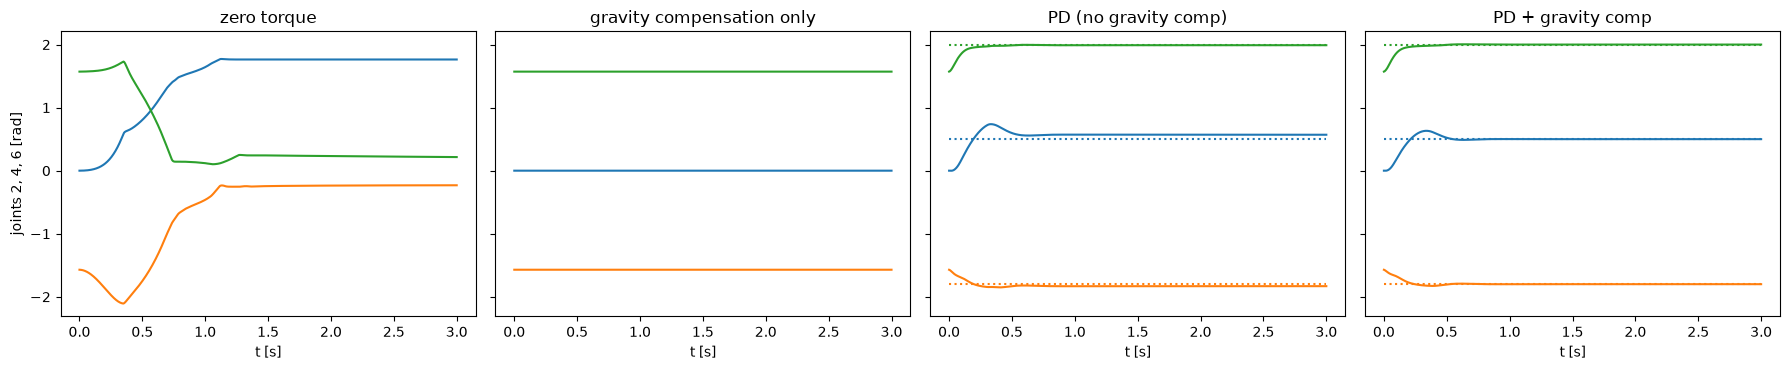

In [2]:
runs = {name: run(c)[0] for name, c in controllers.items()}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
t = np.arange(len(next(iter(runs.values())))) * 0.002
for ax, (name, qs) in zip(axes, runs.items()):
    ax.plot(t[:len(qs)], qs[:, [1, 3, 5]])
    if "PD" in name:
        ax.hlines(TARGET[[1, 3, 5]], 0, t[len(qs) - 1], colors=["C0", "C1", "C2"], linestyles=":")
    ax.set_title(name); ax.set_xlabel("t [s]")
axes[0].set_ylabel("joints 2, 4, 6 [rad]"); plt.tight_layout(); plt.show()

In [3]:
for name in ["PD (no gravity comp)", "PD + gravity comp"]:
    err = np.abs(runs[name][-1] - TARGET)
    print(f"{name:22s} steady-state error per joint [deg]: {np.degrees(err).round(2)}")
print("\nPD alone: q_err = K_p^-1 g(q), the gravity 'sag'. Gravity feed-forward removes it.")

PD (no gravity comp)   steady-state error per joint [deg]: [0.   4.01 0.4  1.81 0.17 0.57 0.01]
PD + gravity comp      steady-state error per joint [deg]: [0. 0. 0. 0. 0. 0. 0.]

PD alone: q_err = K_p^-1 g(q), the gravity 'sag'. Gravity feed-forward removes it.


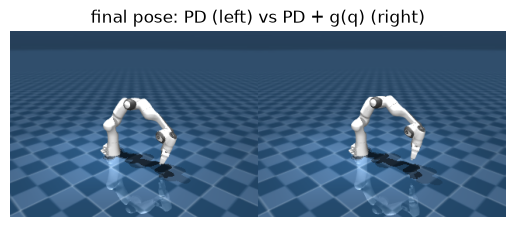

In [4]:
_, frames_nog = run(controllers["PD (no gravity comp)"], render=True)
_, frames_g = run(controllers["PD + gravity comp"], render=True)
show_video([np.hstack([a, b]) for a, b in zip(frames_nog, frames_g)], fps=25, title="PD | PD + gravity compensation")
plt.imshow(np.hstack([frames_nog[-1], frames_g[-1]])); plt.axis("off"); plt.title("final pose: PD (left) vs PD + g(q) (right)"); plt.show()